# Metamodel case generation

Workflow:

1. Load **goals** from `Samoa.json` → `simulations.goals_file`.
2. Generate **Latin Hypercube** cases per goal (`tp`, `wd`, `ds`, `zs`).
3. Build SnapWave case directories from `templates-metamodel`.
4. Run cases (optional) and postprocess to per-goal NetCDF files.

Paths and bounds come from `Samoa.json` → `simulations`.

In [1]:
from bluemath_tk.wrappers.snapwave import SnapWaveMetaModelWrapper
from utils.config import PATHS, SIMULATIONS, load_goals, resolve
from utils import simulation as sim

## Configuration

In [2]:
templates_dir = sim.templates_dir("metamodel")
cases_dir = resolve(SIMULATIONS["metamodel_cases"])
aoi_file = resolve(PATHS["aoi_file"])
mesh_file = resolve(PATHS["mesh_file"])
goals_file = resolve(SIMULATIONS["goals_file"])

print(f"goals     : {goals_file}")
print(f"templates : {templates_dir}")
print(f"cases     : {cases_dir}")
print(f"mesh      : {mesh_file}")
print(f"samples   : {SIMULATIONS['num_samples_per_goal']} per goal")

goals     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/Goals/Samoa_Goals.json
templates : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/templates-metamodel
cases     : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/SnapWave_CASES_Metamodel
mesh      : /home/tausiaj/GitHub-GeoOcean/HyGloW/Samoa/inputs/GRID/Samoa_mesh.nc
samples   : 500 per goal


## LHS cases

In [3]:
raw_goals = load_goals()

cases_df = sim.generate_cases(raw_goals)
cases_df["goal"] = cases_df["goal"].astype(int)
cases_df.head()

,goal,tp,dir,spr,wl
0,1,12.213669,255.248228,18.939314,1.302719
1,1,8.383269,255.032224,13.775162,-2.609729
2,1,6.444611,289.929811,13.077691,0.370466
3,1,5.190768,346.682246,42.685319,3.339651
4,1,7.184247,201.595858,21.310096,2.068328


In [4]:
import numpy as np

# Add a new column called save_map with 5% True
cases_df["save_map"] = np.random.choice(
    [True, False], size=len(cases_df), p=[0.05, 0.95]
)
cases_df.head(20)

,goal,tp,dir,spr,wl,save_map
0,1,12.213669,255.248228,18.939314,1.302719,False
1,1,8.383269,255.032224,13.775162,-2.609729,False
2,1,6.444611,289.929811,13.077691,0.370466,False
3,1,5.190768,346.682246,42.685319,3.339651,False
4,1,7.184247,201.595858,21.310096,2.068328,False
5,1,11.618990,165.107909,38.181303,-0.755730,False
6,1,10.493074,173.127316,21.632372,-1.529876,False
7,1,2.591502,311.425738,27.794586,-1.373622,False
8,1,10.138542,307.402811,10.274056,1.891158,False
9,1,4.274891,299.293740,10.375578,-1.358873,False


In [5]:
cases_df.groupby(["goal", "save_map"])[["tp"]].count()

tp
goal save_map     
1    False     480
     True       20
2    False     476
     True       24
3    False     474
     True       26
4    False     474
     True       26
5    False     474
     True       26
6    False     479
     True       21
7    False     474
     True       26
8    False     464
     True       36
9    False     476
     True       24
10   False     472
     True       28
11   False     470
     True       30
12   False     480
     True       20
13   False     474
     True       26
14   False     473
     True       27
15   False     467
     True       33
16   False     470
     True       30

## SnapWave wrapper

Create the wrapper, then run `plot_configuration()` for a **pre-run diagnostic**:
left side = domain map + direction-range bars per goal; right side = text summary.
Review this before `build_cases()`.

In [6]:
# Case geometry: goals = boundary nodes, AoI enclosure, labelled output sites
setup = sim.SnapWaveCaseSetup.from_case(raw_goals)

wrapper = SnapWaveMetaModelWrapper(
    templates_dir=str(templates_dir),
    metamodel_parameters=cases_df.to_dict(orient="list"),
    fixed_parameters={"gridfile": str(mesh_file)},
    output_dir=str(cases_dir),
    **setup.metamodel_kwargs(),
)
wrapper

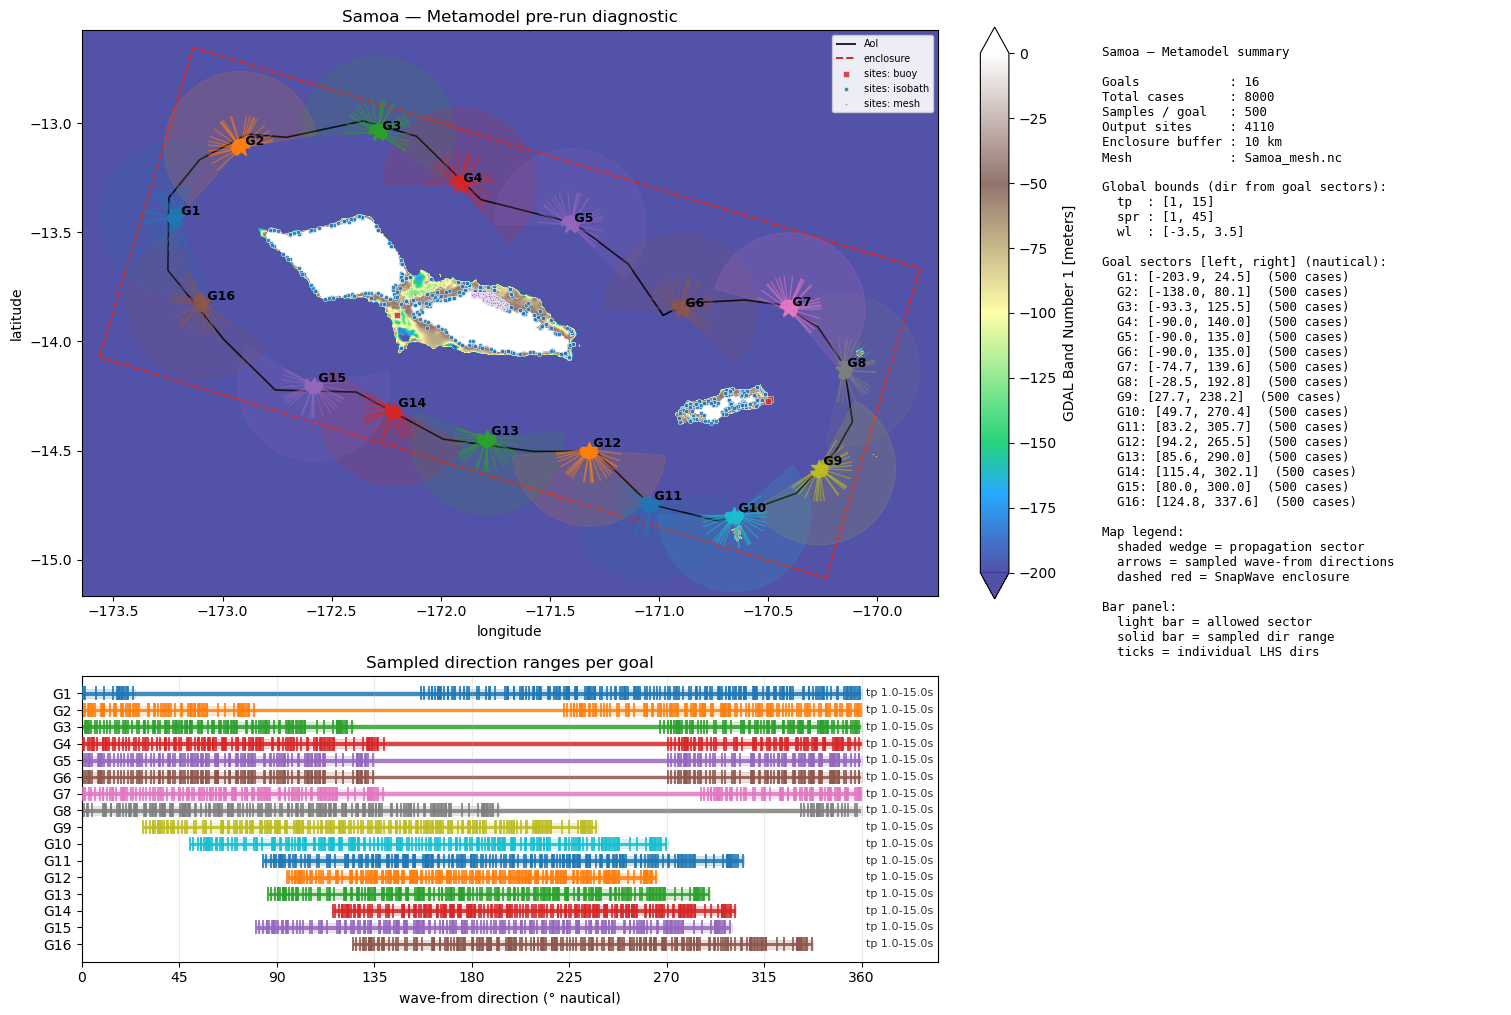

In [7]:
fig = setup.plot_metamodel_configuration(cases_df)
# fig.savefig("metamodel_setup_check.png", dpi=150, bbox_inches="tight")

## Build, run, postprocess

In [8]:
wrapper.load_cases(
    cases_name_format=lambda ctx: f"{ctx.get('goal'):02}/{ctx.get('case_num'):04}"
)

In [16]:
# On the GeoOcean cluster: one SLURM array task per case. Writes case_dirs.txt
# and snapwave_array.sh (module load snapwave, OMP threads, scratch cleanup)
# into the cases folder, then submits it with sbatch.
# wrapper.run_cases_slurm(max_parallel=200)
# Or locally, with snapwave on the PATH:
wrapper.run_cases_in_background(
    launcher="default", num_workers=2, cases_to_run=[3077, 5946]
)

In [9]:
cases_status = wrapper.monitor_cases(value_counts="simple")
cases_status

Status  
FINISHED    8000
Name: count, dtype: int64

## Inspect finished cases

Post-run diagnostic (reads directly from the case folder):

- top row: full-width domain `tripcolor` map (or overview fallback)
- bottom 2×2: `hs`, `tp`, `dir`, `spr` at output sites
- title/subtitle: case id + boundary forcing summary

Customize colormaps via `CasePlotStyle(cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"})`.

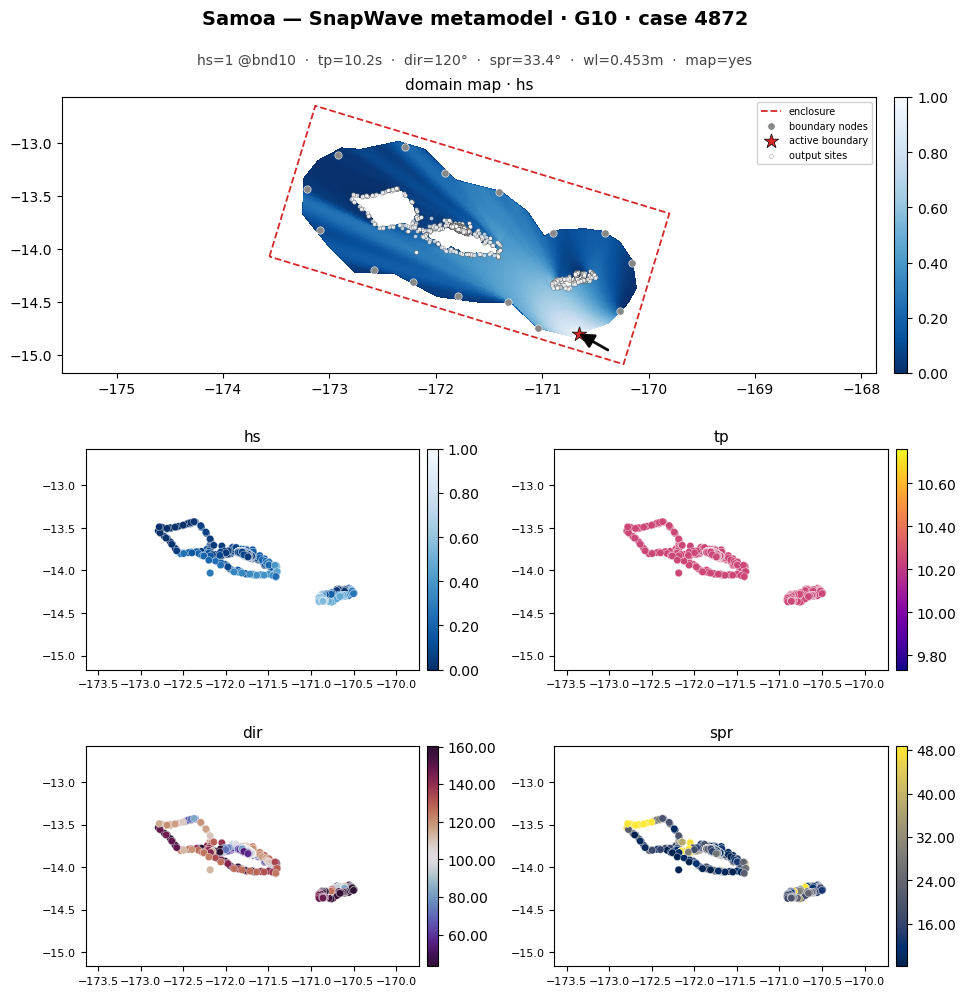

In [11]:
from bluemath_tk.wrappers.snapwave.snapwave_plots import CasePlotStyle
from utils.viz import plot_metamodel_case

style = CasePlotStyle(
    cmaps={"hs": "viridis", "tp": "plasma", "dir": "twilight_shifted", "spr": "cividis"}
)
plot_metamodel_case(cases_dir / "10" / "4872", style=style);

In [20]:
wrapper.postprocess_cases()

'Done'